In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as F
from torch.utils._pytree import tree_map
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import data_loaders
from data_loaders import commit_dataset, CommitedDataset
from dl_trainer import Trainer
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [6]:
try:
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=512, d_embed=128, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=512, d_embed=128, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [70]:
def _plot_tsne_pca_stuff(em, axem, bs, axbs):
    # weights = sklearn.decomposition.PCA(n_components=128).fit_transform(em)
    # weights = sklearn.manifold.TSNE(perplexity=10).fit_transform(weights)
    weights = sklearn.decomposition.PCA(n_components=2).fit_transform(em)
    axem.scatter(weights[:, 0], weights[:, 1], s=1)
    axbs.hist(bs, log=True)



@torch.no_grad()
def plot_tsne_pca_stuff(use_bias=True):
    global item_model, user_model
    item_model.eval(), user_model.eval()
    item_model, user_model = item_model.to('cpu'), user_model.to('cpu')
    _, axs = plt.subplots(2, 2, figsize=(8, 6))
    axs = axs.flatten()

    item_ids = data_model.ratings['item_id'].unique()
    item_feat = data_model.get_item_features(item_ids).astype(np.float32)
    iem, ibs = item_model(torch.tensor(item_ids), torch.tensor(item_feat))
    if not use_bias:
        iem, _ = item_model(torch.tensor(item_ids), torch.tensor(item_feat), use_bias=False)

    axs[0].set_title("Item Embeddings")
    _plot_tsne_pca_stuff(iem.cpu().numpy(), axs[0], ibs.cpu().numpy(), axs[2])
    del item_ids, item_feat, iem, ibs

    user_ids = data_model.ratings['user_id'].unique()
    user_feat = data_model.get_user_features(user_ids).astype(np.float32)
    uem, ubs = user_model(torch.tensor(user_ids), torch.tensor(user_feat))
    if not use_bias:
        uem, _ = user_model(torch.tensor(user_ids), torch.tensor(user_feat), use_bias=False)

    axs[1].set_title("User Embeddings")
    _plot_tsne_pca_stuff(uem.cpu().numpy(), axs[1], ubs.cpu().numpy(), axs[3])
    del user_ids, user_feat, uem, ubs

    plt.show()

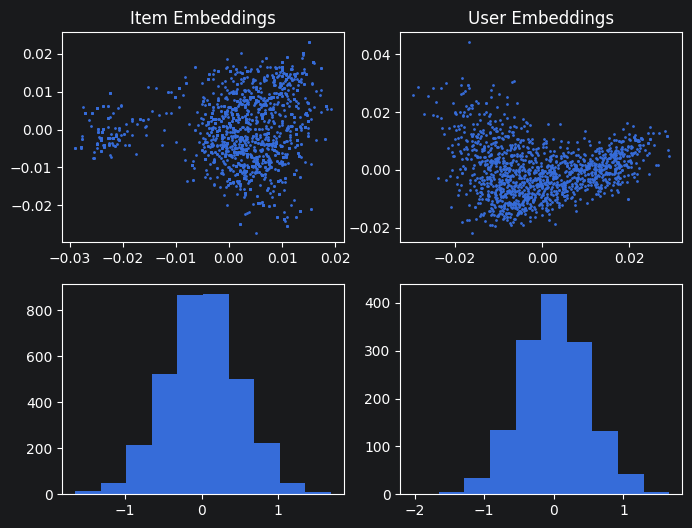

In [8]:
try:
    pass
    plot_tsne_pca_stuff(False)
except:
    traceback.print_exc()

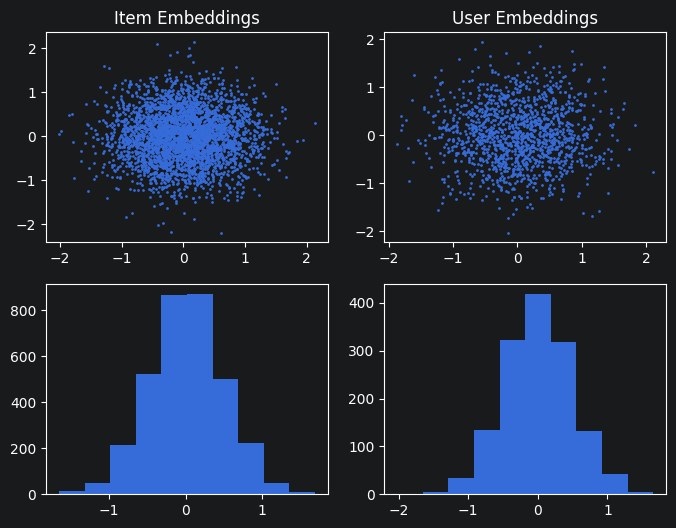

In [9]:
try:
    pass
    plot_tsne_pca_stuff(True)
except:
    traceback.print_exc()

In [10]:
class VVICDatasetIdx(Dataset):
    def __init__(self, data_model: 'DataModel', ratings=None, paravalance=6):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        # self.ratings = self.ratings.sample(frac=1)
        self.median = 0.8
        self.paravalance = paravalance

        self.user_ids = self.ratings['user_id'].to_numpy()
        self.ratings_values = self.ratings['rating'].to_numpy()

        self.user_pos_indices = {}
        self.user_neg_indices = {}

        for idx, (u, r) in enumerate(zip(self.user_ids, self.ratings_values)):
            if r >= self.median:
                if u not in self.user_pos_indices:
                    self.user_pos_indices[u] = []
                self.user_pos_indices[u].append(idx)
            else:
                if u not in self.user_neg_indices:
                    self.user_neg_indices[u] = []
                self.user_neg_indices[u].append(idx)

        for u in self.user_pos_indices:
            self.user_pos_indices[u] = np.array(self.user_pos_indices[u])
        for u in self.user_neg_indices:
            self.user_neg_indices[u] = np.array(self.user_neg_indices[u])

        self.all_indices = np.arange(len(self.ratings))

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id = self.user_ids[idx]

        pos_candidates = self.user_pos_indices[user_id]
        pos_id = pos_candidates[np.random.randint(len(pos_candidates))]

        neg_ids = np.random.choice(self.user_neg_indices[user_id], size=self.paravalance)

        return user_id, pos_id, neg_ids


class VVICDataset(Dataset):
    def __init__(self, idx_data: VVICDatasetIdx, data_model: 'DataModel'):
        self.idx_data = idx_data
        self.data_model = data_model

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.data_model.get_user_features(user_id)

        pos_item_id, pos_item_rating = self.data_model.ratings.iloc[pos_id][['item_id', 'rating']]
        pos_item_feat = self.data_model.get_item_features(pos_item_id)

        neg_item_data = []
        neg_item_ratings = []
        for neg_id in neg_ids:
            neg_item_id, neg_item_rating = data_model.ratings.iloc[neg_id][['item_id', 'rating']]
            neg_item_feat = self.data_model.get_item_features(neg_item_id)
            neg_item_data.append((neg_item_id, neg_item_feat))
            neg_item_ratings.append(neg_item_rating.astype(np.float32))

        return (
            (
                user_id, user_feat,
                pos_item_id, pos_item_feat,
                neg_item_data
            ),
            (
                pos_item_rating.astype(np.float32),
                neg_item_ratings
            )
        )


class VVICDatasetV2(Dataset):
    def __init__(self, idx_data, data_model):
        self.idx_data = idx_data
        self.data_model = data_model

        df = data_model.ratings

        self.item_ids = df['item_id'].to_numpy()
        self.ratings = df['rating'].to_numpy(dtype=np.float32)

        self.user_features = data_model.user_features.sort_index().to_numpy()
        self.item_features = data_model.item_features.sort_index().to_numpy()

    def __len__(self):
        return self.data_model.ratings.shape[0]
        # return 100

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.user_features[user_id]
        pos_item_id = self.item_ids[pos_id]
        pos_item_feat = self.item_features[pos_item_id]
        pos_rating = self.ratings[pos_id]

        neg_item_ids = self.item_ids[neg_ids]
        neg_item_feats = [self.item_features[i].astype(np.float32) for i in neg_item_ids]
        neg_ratings = tuple(self.ratings[neg_ids])

        neg_item_data = tuple(zip(neg_item_ids, neg_item_feats))

        return (
            (
                user_id, user_feat.astype(np.float32),
                pos_item_id, pos_item_feat.astype(np.float32),
                neg_item_data
            ),
            (
                pos_rating,
                # THIS DATA IS USELESS AS IT"S NOT IN THE PERSPECTIVE OF THE USER< THEREFROE WE ASSUME IT 0 ANYWAYS
                neg_ratings
            )
        )


try:
    vvic = VVICDatasetV2(VVICDatasetIdx(data_model), data_model)
    (uid, uft, pii, pif, nid), (pir, nirs) = vvic[0]
    print("User", uid.dtype, uid, uft.dtype, uft.shape)
    print("PosI", pii.dtype, pii, pif.dtype, pif.shape, pir.dtype, pir)
    for (nii, nif), nirs in zip(nid, nirs):
        print("NegI", nii.dtype, nii, nif.dtype, nif.shape, nirs.dtype, nirs)
    print("AcNI", np.mean(nirs))
except:
    traceback.print_exc()

User int64 1520 float32 (1582,)
PosI int64 4729 float32 (429,) float32 3.9824092
NegI int64 9670 float32 (429,) float32 0.7038767
NegI int64 1095 float32 (429,) float32 0.0673879
NegI int64 8655 float32 (429,) float32 0.69341487
NegI int64 1667 float32 (429,) float32 0.6358101
NegI int64 468 float32 (429,) float32 0.6000324
NegI int64 6441 float32 (429,) float32 0.2750618
AcNI 0.2750618


In [11]:
try:
    if False:
        commit_dataset(VVICDatasetIdx(data_model), "VVICDatasetIdx", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [12]:
try:
    if False:
        vvic = VVICDataset(CommitedDataset('VVICDatasetIdx', os.path.join('..', 'temp', 'commited_datasets')), data_model)
except:
    traceback.print_exc()

In [13]:
try:
    if False:
        commit_dataset(vvic, "VVICDatasetNeg", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [14]:
try:
    if True:
        vvic = CommitedDataset('VVICDatasetNeg', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [89]:
def model_train_step(model, data):
    uid, uft, pii, pif, nid = data
    pos_score = model(uid, uft, pii, pif)[0]
    neg_scores = [model(uid, uft, nii, nif)[0] for nii, nif in nid]
    return pos_score, neg_scores


def model_criteria_step(criterion, preds, truth, weight=0.38):
    pos_score, neg_scores = preds
    pir, _ = truth  # nirs ignored since it's not in the perspective of the user!
    nir = pir.new_tensor([0.0])

    return criterion(pos_score, pir) + weight * sum(criterion(nsc, nir) for nsc in neg_scores) / len(neg_scores)


def model_criteria_step_ranking(criterion, preds, truth, weight=0.38):
    pos_score, neg_scores = preds
    return sum([loss_fn_ranking(pos_score / 0.2, nsc / 0.2) for nsc in neg_scores])


def loss_fn_mse_only(preds, truth):
    median = torch.log1p(truth.new_tensor(0.8))
    return F.mse_loss(preds, torch.log1p(truth) - median)


def loss_fn_ranking(positive_score, negative_score):
    return -torch.log(torch.sigmoid(positive_score - negative_score)).mean()


def running_average(arr, window=20):
    return np.convolve(arr, np.ones(window), 'valid') / window

## Training the model with focus only on feature based embeddings

Basically asking it to learn the task as closely as possible using only the user and item features

In [16]:
try:
    pre_training_loss = locals().get('pre_training_loss', None)
    # pre_training_loss = None
    pre_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192, shuffle=False),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.01),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=pre_training_loss,
    )
    pre_training_loss = pre_trainer.loss
    pre_trainer.load_model('model_pretrained_feature_embedder_v3_128.pt')
except:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_12144\4094738054.py", line 17, in <module>
    pre_trainer.load_model('model_pretrained_feature_embedder_v3_128.pt')
    ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\dl_trainer\trainer.py", line 375, in load_model
    self.model.load_state_dict(torch.load(model_path, weights_only=True))
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\torch\nn\modules\module.py", line 2639, in load_state_dict
    raise RuntimeError(
    ...<3 lines>...
    )
RuntimeError: Error(s) in loading state_dict for TwoTowerRecommender:
	Unexpected key(s) in state_dict: "user_model.adaptor.8.weight", "user_model.adaptor.8.bias", "item_model.adaptor.8.weight", "item_model.adaptor.8.bias". 


In [92]:
try:
    pass
    pre_trainer.epochs = 4
    # pre_trainer.dataset_fraction = None
    pre_trainer.model_criteria_step = model_criteria_step
    pre_trainer.model_criteria_step = model_criteria_step_ranking
    # # pre_trainer.load_model('model_pretrained_feature_embedder_v3.pt')
    pre_trainer.learning_rate(0.00001)
    # pre_trainer.checkpoint_frequency_batch = 30
    # pre_trainer.model_criteria_step = model_criteria_step
    pre_trainer.device = 'cuda'
    # pre_trainer.train_dataloader = DataLoader(vvic, batch_size=4096, shuffle=False)
except:
    traceback.print_exc()

In [93]:
try:
    model.prepare_for_feature_based_embeds_training()
    # TODO: Experiment with a lower dropout
    pre_trainer.train()
    # ds v1 CPU 33 sec/it
    # ds v1 GPU 26 sec/it
    # ds v2 GPU 7 sec/it
except:
    traceback.print_exc()

Epoch:  0/ 4    Train Loss: 3.12    TTS: 1.47    ETA: 714.94
Epoch:  0/ 4    Train Loss: 3.17    TTS: 2.44    ETA: 593.21
Epoch:  0/ 4    Train Loss: 3.14    TTS: 3.35    ETA: 540.80
Epoch:  0/ 4    Train Loss: 3.09    TTS: 4.32    ETA: 522.94
Epoch:  0/ 4    Train Loss: 3.14    TTS: 5.30    ETA: 512.43
Epoch:  0/ 4    Train Loss: 3.14    TTS: 6.19    ETA: 497.11
Epoch:  0/ 4    Train Loss: 3.09    TTS: 7.19    ETA: 494.04
Epoch:  0/ 4    Train Loss: 3.12    TTS: 8.11    ETA: 486.57
Epoch:  0/ 4    Train Loss: 3.11    TTS: 9.08    ETA: 483.18
Epoch:  0/ 4    Train Loss: 3.11    TTS: 10.89    ETA: 472.37
Epoch:  0/ 4    Train Loss: 3.12    TTS: 11.81    ETA: 468.30
Epoch:  0/ 4    Train Loss: 3.08    TTS: 12.66    ETA: 462.60
Epoch:  0/ 4    Train Loss: 3.08    TTS: 13.60    ETA: 460.44
Epoch:  0/ 4    Train Loss: 3.14    TTS: 14.58    ETA: 459.90
Epoch:  0/ 4    Train Loss: 3.12    TTS: 15.50    ETA: 457.16
Epoch:  0/ 4    Train Loss: 3.13    TTS: 16.44    ETA: 455.37
Epoch:  0/ 4    T

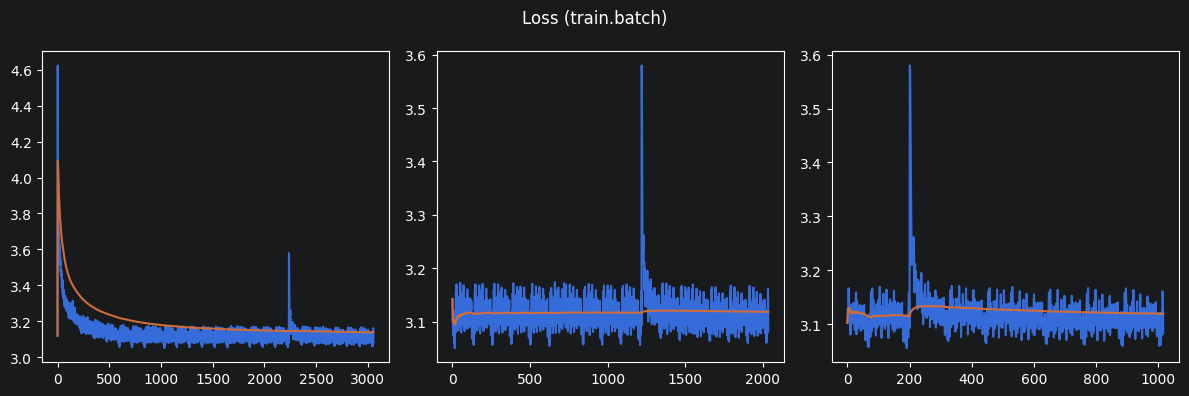

In [96]:
try:
    pre_trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

In [97]:
try:
    # pre_trainer.loss['train.batch'] = pre_trainer.loss['train.batch'][1500:]
    print(len(pre_trainer.loss['train.batch']))
except:
    traceback.print_exc()

3054


In [98]:
try:
    for key in pre_trainer.timer.timers:
        print(key, pre_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 462.6070225499989
_train_step 115.76986141304366
train_dataloader 0.8222945585269814
batch 0.12580842622791888


In [99]:
try:
    pre_trainer.save_model("pretrained_feature_embedder_v3_128")
except:
    traceback.print_exc()

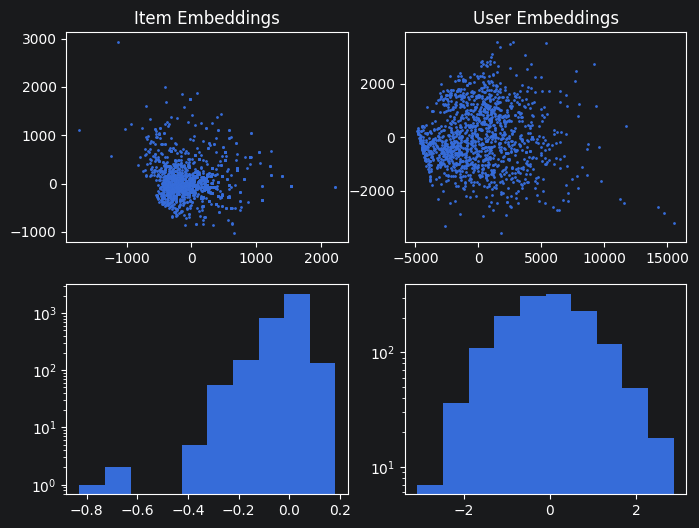

In [100]:
try:
    pass
    plot_tsne_pca_stuff(False)
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [101]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    n_dif = 0
    with torch.no_grad():
        model.prepare_for_feature_based_embeds_training()
        model.eval()
        model.to('cpu')
        temp_ds = DataLoader(vvic, batch_size=8192)
        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            # pos_score, neg_scores = torch.sigmoid(pos_score).numpy(), [torch.sigmoid(x).numpy() for x in neg_scores]
            pos_score, neg_scores = (pos_score).numpy(), [(x).numpy() for x in neg_scores]

            n_pos = n_pos + (pos_score > 0.0).sum()
            n_neg = n_neg + sum([(x < 0.0).sum() for x in neg_scores])
            n_dif = n_dif + (pos_score > neg_scores).sum()

            # n_pos = n_pos + (pos_score > neg_scores).sum()
            # n_neg = n_neg + (pos_score < neg_scores).sum()
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))

    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))
    print("DIFF SCORES")
    print("Diff    : ", n_dif)

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:15<00:00,  1.54s/it]

POS SCORES
Accuracy:  0.08164512573890392
Avg Weig:  0.5444463
NEG SCORES
Accuracy:  0.06532311391644124
Avg Weig:  0.34616983
DIFF SCORES
Diff    :  350583


In [102]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
    print("DIFF SCORES")
    print("Diff    : ", n_dif / 81920 / 6)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.9947509765625
NEG SCORES
Accuracy:  0.13264770507812498
DIFF SCORES
Diff    :  0.713262939453125


## Training the model with focus only on item based embeddings

Allowing it to learn the the item based embeddings (and bias) to close the gap

In [50]:
try:
    id_training_loss = locals().get('id_training_loss', None)
    id_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.01),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=id_training_loss,
    )
    id_training_loss = id_trainer.loss
    # id_trainer.load_model("model_id_trained_embedder_v3_128.pt")
except:
    traceback.print_exc()

In [112]:
try:
    pass
    # id_trainer.load_model("model_id_trained_embedder_v3.pt")
    id_trainer.epochs = 2
    id_trainer.model_criteria_step = model_criteria_step
    id_trainer.model_criteria_step = model_criteria_step_ranking
    id_trainer.device = 'cuda'
    # id_trainer.train_dataloader = DataLoader(vvic, batch_size=8192)
    id_trainer.learning_rate(0.0003)
except:
    traceback.print_exc()

In [117]:
try:
    model.prepare_for_id_based_embeds_training()
    id_trainer.train()
except:
    traceback.print_exc()

Epoch:  0/ 2    Train Loss: 2.24    TTS: 1.21    ETA: 294.21
Epoch:  0/ 2    Train Loss: 2.23    TTS: 2.15    ETA: 260.38
Epoch:  0/ 2    Train Loss: 2.22    TTS: 3.09    ETA: 248.19
Epoch:  0/ 2    Train Loss: 2.20    TTS: 4.07    ETA: 244.02
Epoch:  0/ 2    Train Loss: 2.21    TTS: 5.95    ETA: 235.88
Epoch:  0/ 2    Train Loss: 2.18    TTS: 6.99    ETA: 236.65
Epoch:  0/ 2    Train Loss: 2.19    TTS: 7.99    ETA: 235.77
Epoch:  0/ 2    Train Loss: 2.18    TTS: 9.17    ETA: 239.37
Epoch:  0/ 2    Train Loss: 2.14    TTS: 10.14    ETA: 237.35
Epoch:  0/ 2    Train Loss: 2.16    TTS: 11.05    ETA: 233.99
Epoch:  0/ 2    Train Loss: 2.18    TTS: 12.00    ETA: 231.98
Epoch:  0/ 2    Train Loss: 2.19    TTS: 13.05    ETA: 231.88
Epoch:  0/ 2    Train Loss: 2.18    TTS: 13.91    ETA: 228.60
Epoch:  0/ 2    Train Loss: 2.21    TTS: 14.85    ETA: 226.76
Epoch:  0/ 2    Train Loss: 2.20    TTS: 15.82    ETA: 225.38
Epoch:  0/ 2    Train Loss: 2.17    TTS: 16.67    ETA: 222.55
Epoch:  0/ 2    

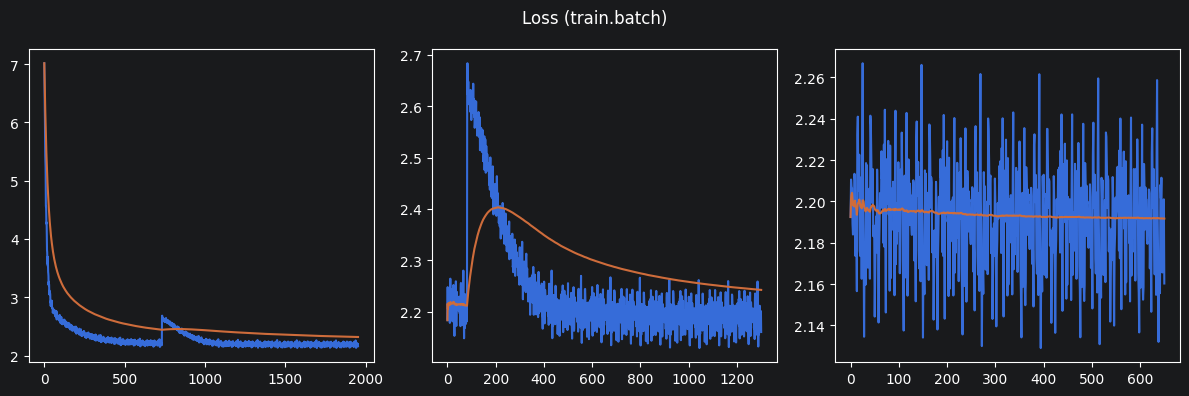

In [121]:
try:
    id_trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

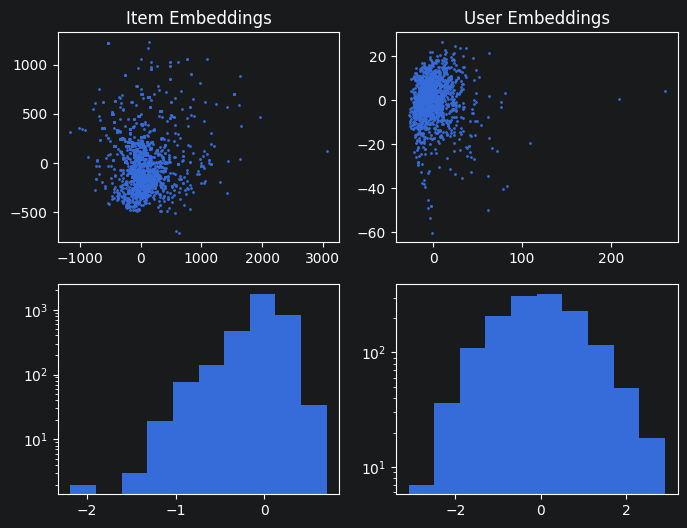

In [122]:
try:
    plot_tsne_pca_stuff(True)
except:
    traceback.print_exc()

In [123]:
try:
    # id_trainer.loss['train.batch'] = id_trainer.loss['train.batch'][3000:]
    print(len(id_trainer.loss['train.batch']))
except:
    traceback.print_exc()

1952


In [124]:
try:
    for key in id_trainer.timer.timers:
        print(key, id_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 234.07037031250002
_train_step 116.99526424374994
train_dataloader 0.8394640869365022
batch 0.11905602377050367


In [125]:
try:
    id_trainer.save_model("id_trained_embedder_v3_128")
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [126]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    n_dif = 0
    diffs = 0
    with torch.no_grad():
        model.prepare_for_id_based_embeds_training()
        model.eval()
        d = torch.device('cpu')
        model.to(d)
        temp_ds = DataLoader(vvic, batch_size=8192)

        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            (uid, uft, pii, pif, nid), (pir, nirs) = tree_map(lambda x: x.to(d), ((uid, uft, pii, pif, nid), (pir, nirs)))
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            pos_score, neg_scores = pos_score.cpu().numpy(), [x.cpu().numpy() for x in neg_scores]
            n_pos = n_pos + (pos_score > 0.5).sum()
            n_neg = n_neg + sum([(x < 0.5).sum() for x in neg_scores])
            n_dif = n_dif + (pos_score > neg_scores).sum()
            diffs += (pos_score - neg_scores).mean()
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))
    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))
    print("DIFF SCORES")
    print("Diff    : ", n_dif)

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:15<00:00,  1.57s/it]

POS SCORES
Accuracy:  0.04436930167317904
Avg Weig:  0.59530133
NEG SCORES
Accuracy:  0.3034906322011822
Avg Weig:  0.16777916
DIFF SCORES
Diff    :  405379


In [127]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
    print("DIFF SCORES")
    print("Diff    : ", n_dif / 81920 / 6)
    print("Diff    : ", diffs / 10)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.54058837890625
NEG SCORES
Accuracy:  0.6162801106770833
DIFF SCORES
Diff    :  0.8247456868489583
Diff    :  0.42752218


## Hmmm...

In [138]:
try:
    with torch.no_grad():
        model.eval()
        idx = random.randint(1, 1000)
        print(idx)  # 121
        (uid, uft, pii, pif, nid), (pir, nirs) = vvic[143]
        nid, nif = nid[0]
        nir = nirs[0]
        # (uid, uft, pii, pif, nid, nif), (pr, nr) = vvic[idx]
        uid, uft, pii, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pii], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        print("User ID:", uid)
        print("Pos  ID:", pii)
        print("Neg  ID:", nid)
        uem, _ = user_model(uid, uft, use_bias=False)
        pie, _ = item_model(pii, pif, use_bias=False)
        nie, _ = item_model(nid, nif, use_bias=False)
        print("Feat Only Dot Pos:", (uem * pie).sum(dim=1))
        print("Feat Only Dot Neg:", (uem * nie).sum(dim=1))
        uem, ubs = user_model(uid, uft, use_bias=True)
        pie, pib = item_model(pii, pif, use_bias=True)
        nie, nib = item_model(nid, nif, use_bias=True)
        print("With ID   Dot Pos:", (uem * pie).sum(dim=1) + ubs + pib)
        print("With ID   Dot Neg:", (uem * nie).sum(dim=1) + ubs + nib)
        model.prepare_for_feature_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model FO      Pos:", pos)
        print("Model FO      Neg:", neg)
        model.prepare_for_id_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model WB      Pos:", pos)
        print("Model WB      Neg:", neg)
        print("Ground Truth  Pos:", pir - np.log1p(0.8))
        print("Ground Truth  Neg:", nir - np.log1p(0.8))
except:
    traceback.print_exc()

145
User ID: tensor([6018])
Pos  ID: tensor([10019])
Neg  ID: tensor([6898])
Feat Only Dot Pos: tensor([157.4749])
Feat Only Dot Neg: tensor([70.8430])
With ID   Dot Pos: tensor([156.8489])
With ID   Dot Neg: tensor([-126.5037])
Model FO      Pos: tensor([0.9702])
Model FO      Neg: tensor([5.2846])
Model WB      Pos: tensor([0.7467])
Model WB      Neg: tensor([-12.7528])
Ground Truth  Pos: 0.4180301523815113
Ground Truth  Neg: -0.05198656552925529


In [139]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        uid = data_model.ratings['user_id'].sample(1).iloc[0]
        print("User ID", uid)
        subset = data_model.ratings[data_model.ratings['user_id'] == uid]
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor([uid]), torch.tensor(uft)
        uem, ubs = user_model(uid, uft)

        iid = subset['item_id'].values
        ift = data_model.get_item_features(iid)
        iid, ift = torch.tensor(iid), torch.tensor(ift)
        iem, ibs = item_model(iid, ift)

        grt = subset['rating'].values

        prt = (uem * iem).sum(dim=1)
        print(prt.shape)
        print(prt.mean(), prt.min(), prt.max(), prt.std())

        for g, p in zip(grt, prt):
            print(g, p.item())

        # results = []
        #
        # for sample in subset.itertuples():
        #     iid = sample.item_id
        #     ift = data_model.get_item_features(iid)
        #     iid, ift = torch.tensor([iid]), torch.tensor(ift)
        #
        #     results.append((sample.rating, model(uid, uft, pii, pif)[0].item()))
        #     print(sample.rating, ",", model(uid, uft, pii, ift)[0].item(), ",", model(None, uft, None, ift)[0].item())

except:
    traceback.print_exc()

User ID 4352
torch.Size([708])
tensor(4964.9292) tensor(-5039.9541) tensor(17628.2188) tensor(2879.2998)
0.6593989874244651 4902.7783203125
0.6563410685375067 5924.806640625
1.2863065326633163 3022.02783203125
0.0 3497.46240234375
0.4600590392700599 7371.84375
0.538421653012548 5525.5556640625
1.067331450758913 6338.6162109375
0.4100058513750731 1792.0045166015625
0.4413906710594763 4012.580322265625
1.6824858757062149 8779.466796875
0.4314733648010789 7132.87646484375
1.2321535692861427 3300.05517578125
1.2923076923076924 3909.50732421875
0.6415610467766937 2526.468505859375
1.0716556291390729 4047.68408203125
1.6675457392450963 2034.8118896484375
0.5641797702687632 7156.310546875
0.3906329113924051 6319.72412109375
1.2999837846602886 4220.95751953125
0.3930041152263374 5933.1162109375
0.5140981073773658 7219.00830078125
0.6890612524238622 3909.568115234375
1.2006356773937228 7182.62841796875
0.4640698455339154 7369.99755859375
0.4588940404839986 2542.272705078125
0.0524746741780278 3

In [49]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        iid = data_model.ratings['item_id'].sample(100).values
        ift = data_model.get_item_features(iid)
        iid, ift = torch.tensor(iid), torch.tensor(ift)

        iem, ibs = item_model(iid, ift)
        print(iem.std(dim=0).mean())

        uid = data_model.ratings['user_id'].sample(100).values
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor(uid), torch.tensor(uft)

        uem, ubs = user_model(uid, uft)
        print(uem.std(dim=0).mean())
        print(uem.norm(dim=-1).mean())
except:
    traceback.print_exc()

tensor(0.2285)
tensor(0.0325)
tensor(1.0386)


In [153]:
try:
    with torch.no_grad():
        model.eval()
        user_model.eval()
        item_model.eval()

        uid = data_model.ratings['user_id'].sample(1).iloc[0]
        print("User ID", uid)
        subset = data_model.ratings[data_model.ratings['user_id'] == uid]
        uft = data_model.get_user_features(uid)
        uid, uft = torch.tensor([uid]), torch.tensor(uft)

        print(user_model(None, uft)[0].shape)

except:
    traceback.print_exc()

User ID 6330
torch.Size([1, 128])


# Oi?

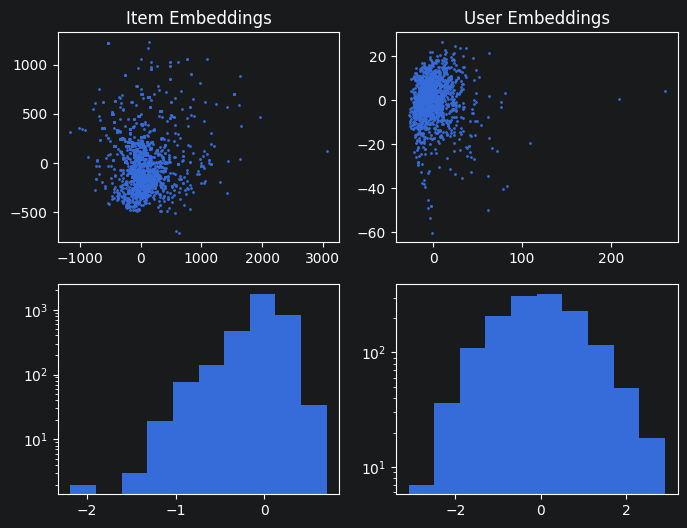

In [140]:
try:
    plot_tsne_pca_stuff()
except:
    traceback.print_exc()